# Investigating the Mersenne Twister

This notebook provides the working code for Assignment 3, Question 2. You will use NumPy's implementation of the **Mersenne Twister** pseudorandom-number generator to investigate reproducibility, uniformity, and statistical convergence.

A pseudorandom-number generator is deterministic: a starting value called the **seed** determines the entire sequence. The sequence can nevertheless have statistical properties that make it useful for simulations.

The goal is to investigate the output empirically. You do **not** need to implement the Mersenne Twister algorithm.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 12

## Creating the generator

NumPy's modern `default_rng()` uses a different algorithm by default. To make this investigation specifically about the Mersenne Twister, we explicitly construct an `MT19937` bit generator.

In [3]:
def make_mersenne_twister(seed):
    # Return a NumPy random-number generator using MT19937.
    return np.random.Generator(np.random.MT19937(seed))

## Part a Reproducibility and the seed

The following cell creates two generators using the same seed and one generator using a different seed. Run it and compare the three sequences.

In [4]:
SEED = 441

rng_a = make_mersenne_twister(SEED)

values_a = rng_a.random(10)

print("First generator, seed 441:")
print(values_a)


First generator, seed 441:
[0.17678155 0.67420814 0.75985841 0.35877555 0.14738443 0.77007201
 0.45852638 0.72038949 0.11526713 0.34840785]


### Your observations

1. What happens when two generators use the same seed?
2. What happens when the seed is changed?
3. What do these results demonstrate about pseudorandom numbers and reproducibility?

Write your response in a new Markdown cell below this one.

## Part b Uniform samples

For a continuous uniform distribution between zero and one, the theoretical mean and variance are

$$
\mu = \frac{1}{2}, \qquad \sigma^2 = \frac{1}{12}.
$$

The next cells generate samples for four values of $N$, calculate their statistics, and plot their histograms.

In [6]:
sample_sizes = [100, 1_000]
theoretical_mean = 1 / 2
theoretical_variance = 1 / 12

# Re-create the generator so this section gives the same results each time.
rng = make_mersenne_twister(SEED)

samples = {}
rows = []

for n in sample_sizes:
    sample = rng.random(n)
    samples[n] = sample
    rows.append(
        {
            "N": n,
            "sample mean": np.mean(sample),
            "sample variance": np.var(sample),
            "mean absolute error": abs(np.mean(sample) - theoretical_mean),
            "variance absolute error": abs(np.var(sample) - theoretical_variance),
        }
    )

results = pd.DataFrame(rows)
results

,N,sample mean,sample variance,mean absolute error,variance absolute error
0,100,0.446154,0.079066,0.053846,0.004267
1,1000,0.494179,0.084042,0.005821,0.000709


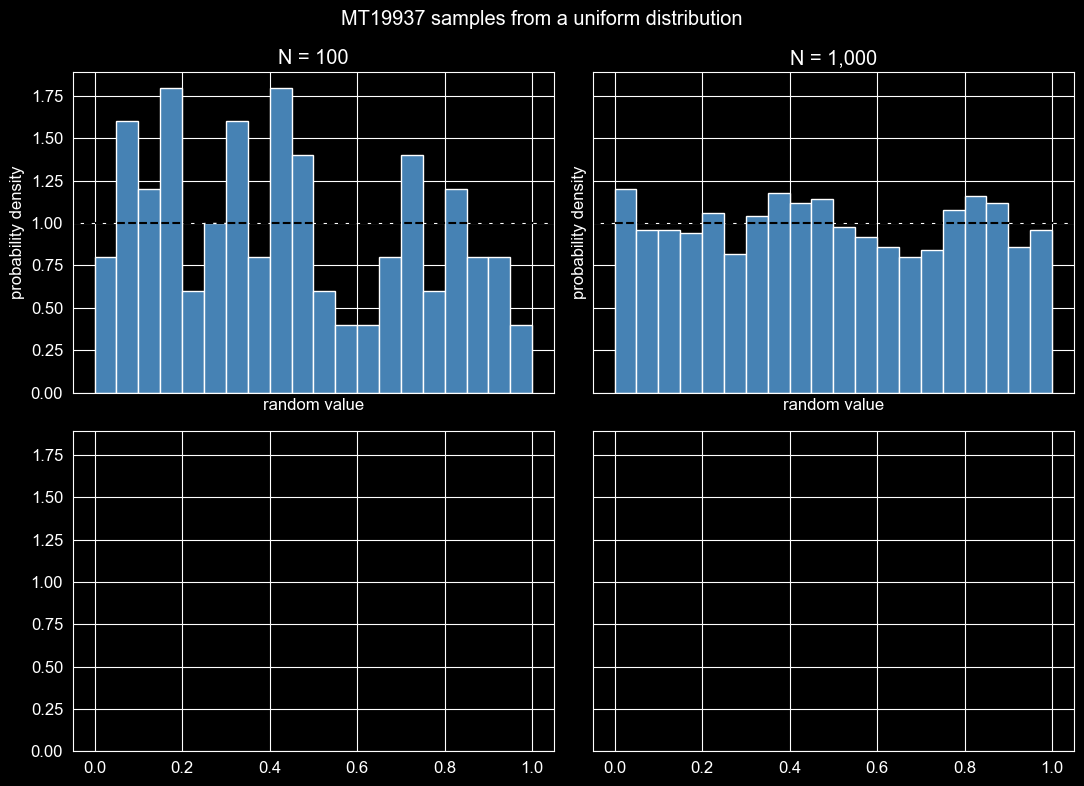

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, n in zip(axes.flat, sample_sizes):
    ax.hist(samples[n], bins=20, range=(0, 1), density=True,
            color="steelblue", edgecolor="white")
    ax.axhline(1.0, color="black", linestyle="--", label="uniform density")
    ax.set_title(f"N = {n:,}")
    ax.set_xlabel("random value")
    ax.set_ylabel("probability density")

fig.suptitle("MT19937 samples from a uniform distribution")
fig.tight_layout()
plt.show()

### Your observations

1. How does the histogram change as the sample size increases?
2. How close are the sample mean and variance to their theoretical values for each sample size?

Record the requested values and your observations in your submitted notebook.

## Part c Error as a function of sample size

The cell below plots the absolute errors from the table. Because random fluctuations are not guaranteed to decrease smoothly at every step, concentrate on the overall scale and trend rather than expecting a perfectly straight or decreasing curve.

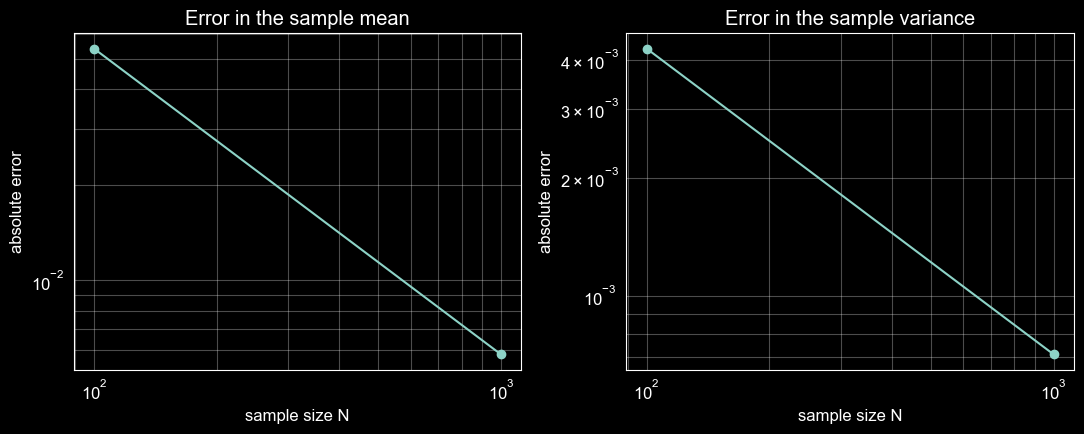

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].loglog(results["N"], results["mean absolute error"], "o-")
axes[0].set_xlabel("sample size N")
axes[0].set_ylabel("absolute error")
axes[0].set_title("Error in the sample mean")
axes[0].grid(True, which="both", alpha=0.3)

axes[1].loglog(results["N"], results["variance absolute error"], "o-")
axes[1].set_xlabel("sample size N")
axes[1].set_ylabel("absolute error")
axes[1].set_title("Error in the sample variance")
axes[1].grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.show()

### Your observations

Describe how the agreement with the theoretical mean and variance changes as the sample size increases. Do not be concerned if one error occasionally increases when moving from one sample size to the next.

## Part d Conclusions

Add a final Markdown cell that answers the following questions in your own words:

1. Why is a pseudorandom-number generator useful in a scientific simulation?
2. Why is it important to record the seed used in a simulation?
3. Why do the tests in this notebook not prove that the generator is perfectly random?

Before submitting, use **Kernel → Restart Kernel and Run All Cells** to confirm that the notebook runs from beginning to end.